# ElimuSentry, Phase 2: pipeline execution and visual diagnostics

This notebook carries out the plan in `phase1_strategy/Phase1_Strategy_Report.pdf`:

1. load the two tables and apply the fixed rules (inflation adjustment);
2. split **X_train / X_test** strictly by time, and set the overlap children aside;
3. fit the scikit-learn **Pipeline + ColumnTransformer** (`src/pipeline_builder.py`) on X_train only;
4. produce the **8 diagnostic figures** (saved to `figures/` at 300 DPI);
5. verify the output (final size, no missing values, no information lost when 33 features become 30);
6. run the checks promised in Phase 1 and a quick 5-fold run that checks the pipeline works end to end;
7. save the processed data and the decision log used in `Phase2_Final_Report.pdf`.

Run the cells from top to bottom. The two input tables are built by `notebooks/01_build_dataset.ipynb`.

## 1. Setup

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno
from scipy import stats
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import average_precision_score, roc_auc_score

warnings.filterwarnings("ignore", category=UserWarning)

# locate the repository root (the folder that contains src/)
ROOT = Path.cwd()
while not (ROOT / "src").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.transformers import deflate_to_2009_prices, CPI_FACTOR_W2_TO_W1, MissedHoursRule
from src.pipeline_builder import (build_pipeline, default_estimator, ID_COLS, TARGET,
                                  FEATURES_30)

PROC = ROOT / "data" / "processed"
FIG = ROOT / "figures"
OUT = ROOT / "phase2_implementation"
FIG.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 300, "font.size": 10})
BLUE, GREY, RED = "#2a6f97", "#b0b7bf", "#c0392b"
print("Repository root:", ROOT)

Repository root: C:\Users\emuhi\Documents\Codex\2026-10-19\referenced-chatgpt-conversation-this-is-an\work\rubric_revision


## 2. Load the data, apply the fixed rules, split X_train / X_test

* **Fixed rule 1** (recording errors) was applied when the tables were built (`01_build_dataset.ipynb`).
* **Fixed rule 2**: 2013/14 money values are converted to 2009/10 prices. Factor = 174.0 / 107.5 = 1.62
  (World Bank consumer price inflation for Ghana, weighted by the months in which interviews took place).
  It is a fixed number, so nothing is learned from the data.
* The split is **by time**: children first seen in 2009/10 are X_train; children first seen in 2013/14 are X_test.
* 220 children appear in both tables. They are kept in X_test but marked, so the main test result can exclude them.

In [2]:
train = pd.read_csv(PROC / "train_w1_w2_raw.csv")
test_raw = pd.read_csv(PROC / "test_w2_w3_raw.csv")
test = deflate_to_2009_prices(test_raw)
print(f"Inflation factor 2013/14 -> 2009/10 prices: {CPI_FACTOR_W2_TO_W1:.3f}")

FEATURES_33 = [c for c in train.columns if c not in ID_COLS + [TARGET]]
X_train, y_train = train.drop(columns=[TARGET]), train[TARGET]
X_test, y_test = test.drop(columns=[TARGET]), test[TARGET]

in_both = set(zip(train["FPrimary"], train["hhmid"]))
test_in_train = pd.Series([k in in_both for k in zip(test["FPrimary"], test["hhmid"])], index=test.index)

print(f"X_train: {X_train.shape[0]} children x {len(FEATURES_33)} features | dropout rate {y_train.mean():.1%}")
print(f"X_test : {X_test.shape[0]} children x {len(FEATURES_33)} features | dropout rate {y_test.mean():.1%}")
print(f"Children in both tables: {test_in_train.sum()} -> secondary person-disjoint set = {(~test_in_train).sum()} children")

from src.evaluation_split import temporal_masks, write_evaluation_protocol
test_cohorts = temporal_masks(train, test_raw)
temporal_audit = write_evaluation_protocol(ROOT, train, test_raw)
print("Primary novel-household test:", int(test_cohorts.in_primary_test.sum()))
print("Secondary person-disjoint test:", int(test_cohorts.in_secondary_test.sum()))
print("Temporal aggregates were explored previously; this is retrospective evaluation, not a pristine holdout.")


Inflation factor 2013/14 -> 2009/10 prices: 1.619
X_train: 1307 children x 33 features | dropout rate 14.4%
X_test : 1395 children x 33 features | dropout rate 10.4%
Children in both tables: 220 -> secondary person-disjoint set = 1175 children
Primary novel-household test: 731
Secondary person-disjoint test: 1175
Temporal aggregates were explored previously; this is retrospective evaluation, not a pristine holdout.


## 3. Figures 1.1 and 1.2: missing answers and the outcome

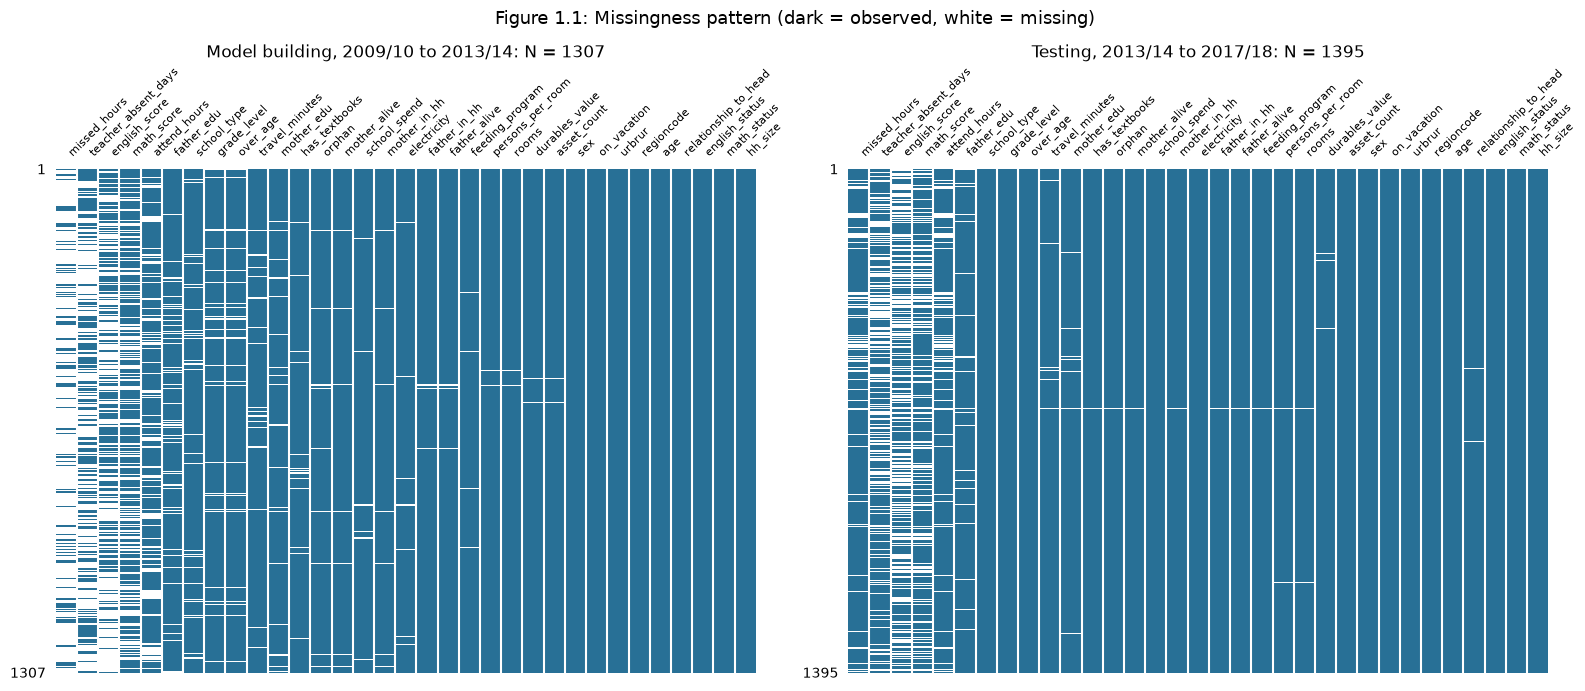

X_train: 3847 of 43131 answers missing (8.92%); complete rows 53 of 1307
X_test: 1827 of 46035 answers missing (3.97%); complete rows 467 of 1395


In [3]:
miss = X_train[FEATURES_33].isna().mean().sort_values(ascending=False)
order = miss.index.tolist()
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, (name, df) in zip(axes, [("Model building, 2009/10 to 2013/14", X_train), ("Testing, 2013/14 to 2017/18", X_test)]):
    msno.matrix(df[order], ax=ax, sparkline=False, fontsize=8, color=(0.16, 0.44, 0.59))
    ax.set_title(f"{name}: N = {len(df)}", fontsize=12)
plt.suptitle("Figure 1.1: Missingness pattern (dark = observed, white = missing)", fontsize=13)
plt.tight_layout()
plt.savefig(FIG / "fig1_1_missingness_heatmap.png", bbox_inches="tight")
plt.show()

for name, df in [("X_train", X_train), ("X_test", X_test)]:
    m = df[FEATURES_33].isna()
    print(f"{name}: {m.values.sum()} of {m.size} answers missing ({m.values.mean():.2%}); "
          f"complete rows {(~m.any(axis=1)).sum()} of {len(df)}")

*How to read Figure 1.1:* each thin row is one child and each column one feature; white marks are missing answers. Columns are sorted from most to least missing in the model-building table.

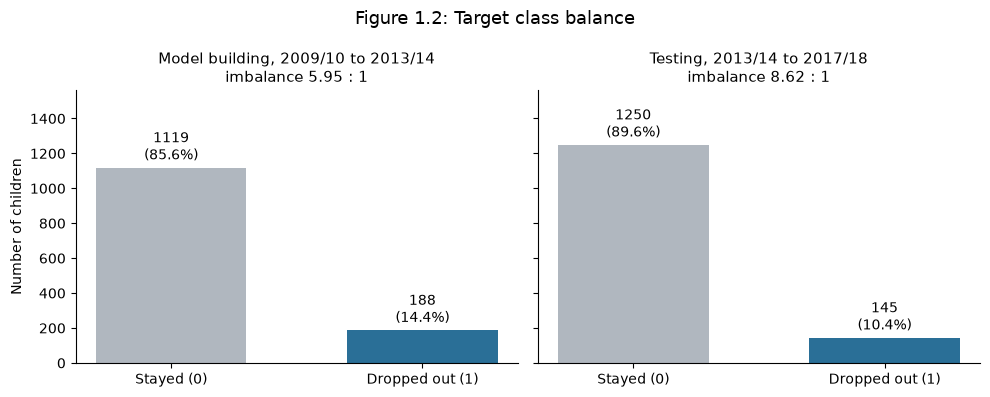

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, (name, y) in zip(axes, [("Model building, 2009/10 to 2013/14", y_train), ("Testing, 2013/14 to 2017/18", y_test)]):
    counts = y.value_counts().reindex([0, 1])
    bars = ax.bar(["Stayed (0)", "Dropped out (1)"], counts.values, color=[GREY, BLUE], width=0.6)
    for b, v in zip(bars, counts.values):
        ax.text(b.get_x() + b.get_width() / 2, v + 20, f"{v}\n({v / len(y):.1%})", ha="center", va="bottom")
    ax.set_title(f"{name}\nimbalance {counts[0] / counts[1]:.2f} : 1", fontsize=11)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Number of children")
axes[0].set_ylim(0, max(len(y_train), len(y_test)) * 1.12)
plt.suptitle("Figure 1.2: Target class balance", fontsize=13)
plt.tight_layout()
plt.savefig(FIG / "fig1_2_target_distribution.png", bbox_inches="tight")
plt.show()

## 4. Fit the pipeline on X_train only, then apply it to X_test

Two versions are built from the same steps (`src/pipeline_builder.py`):
* **XGBoost version**: no log transform and no scaling (trees only compare values).
* **Logistic regression / PCA version**: log on long tails, then `StandardScaler`, one option per label left out.

`fit` learns every setting (medians, modes, KNN neighbours, cap limits, money ranks, encoders, scaler) from **X_train only**; `transform` applies those settings to X_test unchanged.

In [5]:
pre_xgb = build_pipeline("xgb").fit(X_train)
pre_lr = build_pipeline("lr").fit(X_train)

def as_frame(pre, X):
    return pd.DataFrame(pre.transform(X), columns=pre.named_steps["prep"].get_feature_names_out(), index=X.index)

Xtr_xgb, Xte_xgb = as_frame(pre_xgb, X_train), as_frame(pre_xgb, X_test)
Xtr_lr, Xte_lr = as_frame(pre_lr, X_train), as_frame(pre_lr, X_test)

# leakage check: applying the pipeline to X_test must not change anything it learned
import pickle
state = pickle.dumps(pre_xgb); _ = pre_xgb.transform(X_test)
assert pickle.dumps(pre_xgb) == state
print("Leakage check passed: transforming X_test does not change the fitted settings.")
print(pre_xgb)

Leakage check passed: transforming X_test does not change the fitted settings.
Pipeline(steps=[('missed_hours_rule', MissedHoursRule()),
                ('missing_flags', MissingFlagger()),
                ('grade_knn', GradeKNNImputer()),
                ('drop_repeating', ColumnDropper()),
                ('recode', CategoryRecoder()),
                ('prep',
                 ColumnTransformer(transformers=[('mean',
                                                  Pipeline(steps=[('fill',
                                                                   SimpleImputer()),
                                                                  ('scale',
                                                                   'passthrough')]),
                                                  ['english_score',
                                                   'math_score']),
                                                 ('median',
                                                  Pipeli...
 

## 5. Pipeline output verification

In [6]:
checks = {
    "Raw features": len(FEATURES_33),
    "Features after removing 3 repeating ones": len(FEATURES_30),
    "Columns, XGBoost version": Xtr_xgb.shape[1],
    "Columns, logistic regression version": Xtr_lr.shape[1],
    "Rows X_train / X_test": f"{len(Xtr_xgb)} / {len(Xte_xgb)}",
    "Missing values left (train, test)": f"{int(Xtr_xgb.isna().sum().sum())}, {int(Xte_xgb.isna().sum().sum())}",
}
assert len(FEATURES_30) == 30 and Xtr_xgb.shape[1] == 53 and Xtr_lr.shape[1] == 48
assert Xtr_xgb.isna().sum().sum() == 0 and Xte_xgb.isna().sum().sum() == 0
for k, v in checks.items():
    print(f"{k:45s} {v}")

groups = {"numbers or ordered numbers": 16, "yes/no items": 9, "one-hot label columns": 24, "'was missing' flags": 4}
print("\n53 columns =", " + ".join(f"{v} {k}" for k, v in groups.items()))

Raw features                                  33
Features after removing 3 repeating ones      30
Columns, XGBoost version                      53
Columns, logistic regression version          48
Rows X_train / X_test                         1307 / 1395
Missing values left (train, test)             0, 0

53 columns = 16 numbers or ordered numbers + 9 yes/no items + 24 one-hot label columns + 4 'was missing' flags


**No information is lost when 33 features become 30.** Each removed feature can be rebuilt exactly from features that are kept. The check below rebuilds them and counts any child where the rebuilt value differs.

In [7]:
d = train
reconstructed = {
    "school_grade": d.age - d.over_age - 5,
    "lost_a_parent (orphan)": pd.Series(np.select(
        [d.father_alive.eq(0) | d.mother_alive.eq(0), d.father_alive.eq(1) & d.mother_alive.eq(1)],
        [1., 0.], default=np.nan), index=d.index),
    "people_per_room": d.hh_size / d.rooms,
}
originals = {"school_grade": "grade_level", "lost_a_parent (orphan)": "orphan", "people_per_room": "persons_per_room"}
descriptions = {"school_grade": "age - over_age - 5",
                "lost_a_parent (orphan)": "Three-valued parent-alive logic; unknown stays unknown",
                "people_per_room": "household size / rooms"}
rebuild = pd.DataFrame([{"removed feature": name, "rebuilt from kept features": descriptions[name],
    "children checked": len(d), "children that differ": int((~np.isclose(values, d[originals[name]], equal_nan=True)).sum())}
    for name, values in reconstructed.items()])
print(rebuild.to_string(index=False))
assert rebuild["children that differ"].sum() == 0
rebuild.to_csv(OUT / "feature_reconstruction.csv", index=False)
print("This checks the structural feature removal only; capping/ranking intentionally change values.")


       removed feature                             rebuilt from kept features  children checked  children that differ
          school_grade                                     age - over_age - 5              1307                     0
lost_a_parent (orphan) Three-valued parent-alive logic; unknown stays unknown              1307                     0
       people_per_room                                 household size / rooms              1307                     0
This checks the structural feature removal only; capping/ranking intentionally change values.


## 6. Figure 2.1: extreme values before and after capping

The cap limits are the ones the pipeline learned from X_train (IQR fence on the log scale). Money is no longer capped: it is ranked (Phase 1, C1), so only the three capped features are shown.

                upper limit  capped (train)  capped (test)
travel_minutes        294.0               2              0
hh_size                15.2               6              4
rooms                  18.8               5              1
Total capped: 13 (train), 5 (test). No child deleted.


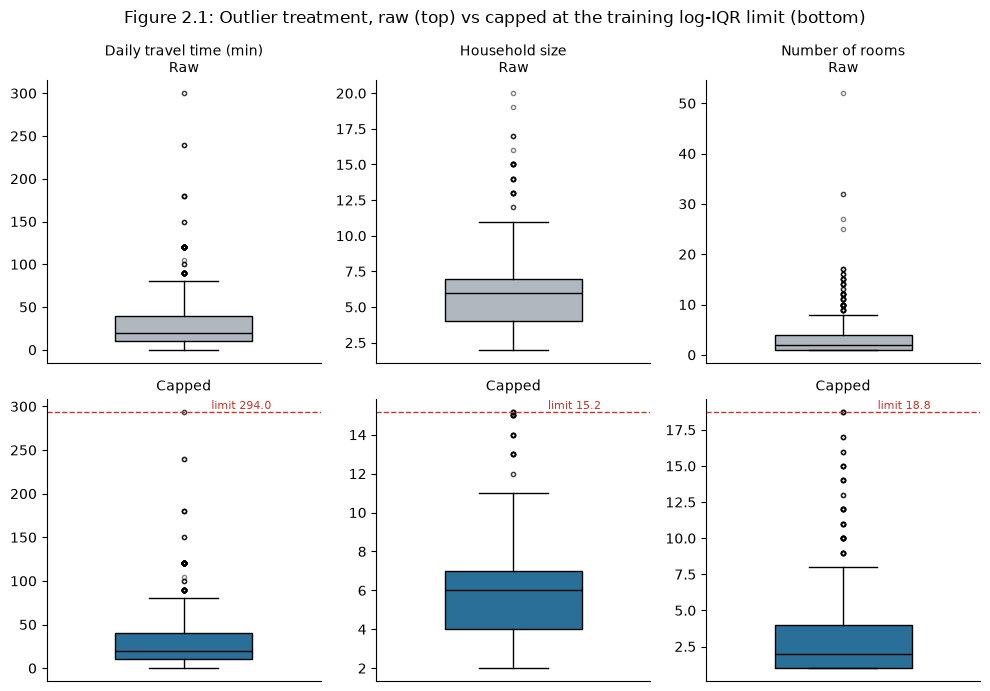

In [8]:
capper = pre_xgb.named_steps["prep"].named_transformers_["cap"].named_steps["cap"]
CAP = ["travel_minutes", "hh_size", "rooms"]
LABEL = {"travel_minutes": "Daily travel time (min)", "hh_size": "Household size", "rooms": "Number of rooms"}
limits = dict(zip(CAP, capper.upper_))
capped_train = {c: int((X_train[c] > limits[c]).sum()) for c in CAP}
capped_test = {c: int((X_test[c] > limits[c]).sum()) for c in CAP}
print(pd.DataFrame({"upper limit": pd.Series(limits).round(1), "capped (train)": capped_train,
                    "capped (test)": capped_test}).to_string())
print("Total capped:", sum(capped_train.values()), "(train),", sum(capped_test.values()), "(test). No child deleted.")

fig, axes = plt.subplots(2, 3, figsize=(10, 7))
for j, c in enumerate(CAP):
    raw = X_train[c].dropna()
    for i, (data, lab) in enumerate([(raw, "Raw"), (raw.clip(upper=limits[c]), "Capped")]):
        ax = axes[i, j]
        ax.boxplot(data, widths=0.5, patch_artist=True, boxprops=dict(facecolor=GREY if i == 0 else BLUE),
                   medianprops=dict(color="black"), flierprops=dict(marker="o", markersize=3, alpha=0.5))
        ax.set_xticks([])
        ax.set_title(f"{LABEL[c]}\n{lab}" if i == 0 else lab, fontsize=10)
        if i == 1:
            ax.axhline(limits[c], color=RED, ls="--", lw=1)
            ax.text(1.32, limits[c], f"limit {limits[c]:.1f}", color=RED, fontsize=8, va="bottom", ha="right")
        ax.spines[["top", "right"]].set_visible(False)
plt.suptitle("Figure 2.1: Outlier treatment, raw (top) vs capped at the training log-IQR limit (bottom)", fontsize=12)
plt.tight_layout()
plt.savefig(FIG / "fig2_1_outlier_boxplots.png", bbox_inches="tight")
plt.show()

## 7. Figures 3.1 and 3.2: features that repeat each other

The brief asks for pairs with |r| ≥ 0.85. Because no feature is bell-shaped, the correlation is measured with **Spearman ρ** (a rank correlation), as planned in Phase 1. The cell also shows Pearson r for the flagged pairs, to make the difference visible.

father_alive vs orphan: Spearman rho = -0.850, Pearson r = -0.850
rooms vs persons_per_room: Spearman rho = -0.855, Pearson r = -0.563


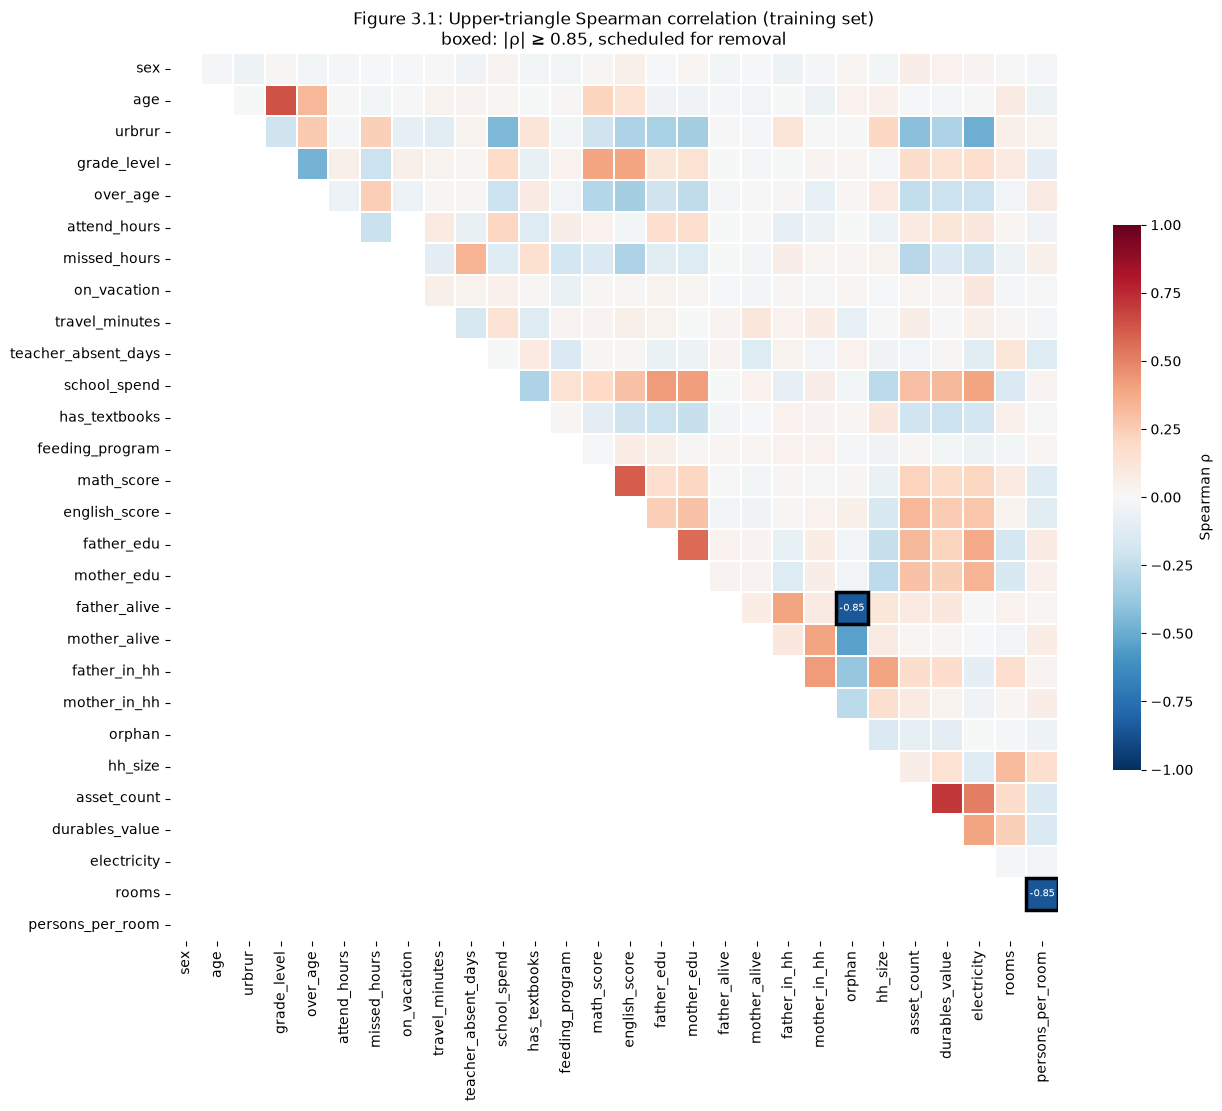

In [9]:
TYPES = {"Nominal": ["regioncode", "school_type", "relationship_to_head", "math_status", "english_status"]}
CORR_FEATS = [c for c in FEATURES_33 if c not in TYPES["Nominal"]]
rho = X_train[CORR_FEATS].corr(method="spearman")
pear = X_train[CORR_FEATS].corr(method="pearson")
pairs = [(a, b, rho.loc[a, b]) for i, a in enumerate(CORR_FEATS) for b in CORR_FEATS[i + 1:] if abs(rho.loc[a, b]) >= 0.85]
for a, b, r in pairs:
    print(f"{a} vs {b}: Spearman rho = {r:+.3f}, Pearson r = {pear.loc[a, b]:+.3f}")

mask = np.tril(np.ones_like(rho, dtype=bool))
fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(rho, mask=mask, cmap="RdBu_r", vmin=-1, vmax=1, center=0, square=True, linewidths=0.3,
            cbar_kws={"shrink": 0.6, "label": "Spearman ρ"}, ax=ax)
for a, b, r in pairs:
    i, j = CORR_FEATS.index(a), CORR_FEATS.index(b)
    ax.add_patch(plt.Rectangle((max(i, j), min(i, j)), 1, 1, fill=False, edgecolor="black", lw=2.5))
    ax.text(max(i, j) + 0.5, min(i, j) + 0.5, f"{r:.2f}", ha="center", va="center", fontsize=7, color="white")
ax.set_title("Figure 3.1: Upper-triangle Spearman correlation (training set)\nboxed: |ρ| ≥ 0.85, scheduled for removal", fontsize=12)
plt.tight_layout()
plt.savefig(FIG / "fig3_1_correlation_matrix.png", bbox_inches="tight")
plt.show()

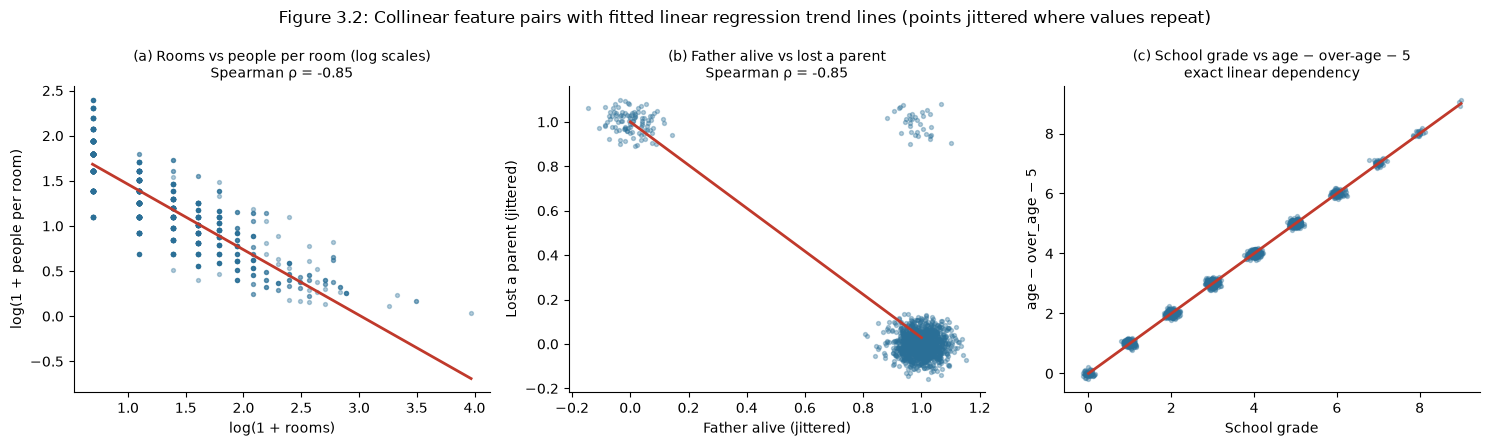

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
rng = np.random.default_rng(0)

d = X_train[["rooms", "persons_per_room"]].dropna()
lx, ly = np.log1p(d["rooms"]), np.log1p(d["persons_per_room"])
axes[0].scatter(lx, ly, s=8, alpha=0.35, color=BLUE)
b1, b0 = np.polyfit(lx, ly, 1); xs = np.linspace(lx.min(), lx.max(), 50)
axes[0].plot(xs, b0 + b1 * xs, color=RED, lw=2)
axes[0].set_xlabel("log(1 + rooms)"); axes[0].set_ylabel("log(1 + people per room)")
axes[0].set_title(f"(a) Rooms vs people per room (log scales)\nSpearman ρ = {d['rooms'].corr(d['persons_per_room'], method='spearman'):+.2f}", fontsize=10)

d = X_train[["father_alive", "orphan"]].dropna()
axes[1].scatter(d["father_alive"] + rng.normal(0, 0.05, len(d)), d["orphan"] + rng.normal(0, 0.05, len(d)), s=8, alpha=0.35, color=BLUE)
b1, b0 = np.polyfit(d["father_alive"], d["orphan"], 1); xs = np.linspace(0, 1, 50)
axes[1].plot(xs, b0 + b1 * xs, color=RED, lw=2)
axes[1].set_xlabel("Father alive (jittered)"); axes[1].set_ylabel("Lost a parent (jittered)")
axes[1].set_title(f"(b) Father alive vs lost a parent\nSpearman ρ = {d['father_alive'].corr(d['orphan'], method='spearman'):+.2f}", fontsize=10)

d = X_train[["grade_level", "age", "over_age"]].dropna()
implied = d["age"] - d["over_age"] - 5
axes[2].scatter(d["grade_level"] + rng.normal(0, 0.08, len(d)), implied + rng.normal(0, 0.08, len(d)), s=8, alpha=0.35, color=BLUE)
b1, b0 = np.polyfit(d["grade_level"], implied, 1); xs = np.linspace(0, 9, 50)
axes[2].plot(xs, b0 + b1 * xs, color=RED, lw=2)
axes[2].set_xlabel("School grade"); axes[2].set_ylabel("age − over_age − 5")
axes[2].set_title("(c) School grade vs age − over-age − 5\nexact linear dependency", fontsize=10)
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
plt.suptitle("Figure 3.2: Collinear feature pairs with fitted linear regression trend lines (points jittered where values repeat)", fontsize=12)
plt.tight_layout()
plt.savefig(FIG / "fig3_2_collinear_scatterplots.png", bbox_inches="tight")
plt.show()

**Check promised in Phase 1 (B4b):** the choice of which feature to drop is re-checked inside each of the 5 folds, using only the building part of the fold. The same three features must be flagged and dropped every time.

In [11]:
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

def mi_one(x, y, discrete):
    ok = x.notna()
    return mutual_info_classif(x[ok].to_numpy().reshape(-1, 1), y[ok], discrete_features=[discrete], random_state=42)[0]

rows = []
for k, (a, _) in enumerate(cv.split(X_train, y_train, groups=X_train["district_id"]), start=1):
    Xa, ya = X_train.iloc[a], y_train.iloc[a]
    r = Xa[CORR_FEATS].corr(method="spearman")
    flagged = sorted({tuple(sorted((p, q))) for p in CORR_FEATS for q in CORR_FEATS if p < q and abs(r.loc[p, q]) >= 0.85})
    # within each flagged pair, drop the feature with less information about dropout
    mi = {c: mi_one(Xa[c], ya, c not in ("persons_per_room", "rooms")) for c in ["persons_per_room", "rooms", "orphan", "father_alive", "grade_level", "age", "over_age"]}
    drop1 = "persons_per_room" if mi["persons_per_room"] < mi["rooms"] else "rooms"
    drop2 = "orphan" if mi["orphan"] < mi["father_alive"] else "father_alive"
    drop3 = min(["grade_level", "age", "over_age"], key=lambda c: mi[c])
    rows.append({"fold": k, "pairs |rho|>=0.85": len(flagged), "drop 1": drop1, "drop 2": drop2, "drop 3": drop3})
fold_drops = pd.DataFrame(rows)
print(fold_drops.to_string(index=False))

 fold  pairs |rho|>=0.85           drop 1       drop 2      drop 3
    1                  1 persons_per_room       orphan grade_level
    2                  1            rooms       orphan grade_level
    3                  2            rooms       orphan grade_level
    4                  2 persons_per_room father_alive         age
    5                  1            rooms       orphan         age


*What this shows:* the pairs and the exact relationship are found in every fold, but which member of a pair carries slightly more information about dropout changes from fold to fold, because the differences in mutual information are tiny (for example 0.0105 vs 0.0177 on the full table, and smaller or reversed inside some folds). Phase 1 anticipated this case: "if similar, keep the one measured directly over one calculated from others". People per room (calculated from rooms and household size) and lost a parent (calculated from the parent-alive items) are therefore removed; in the age, grade and over-age group, over-age (the risk signal) and age are kept and grade is removed. The list is fixed before cross-validation, so it cannot be tuned on the checking parts.

## 8. Figure 3.3: which features tell us most about dropout

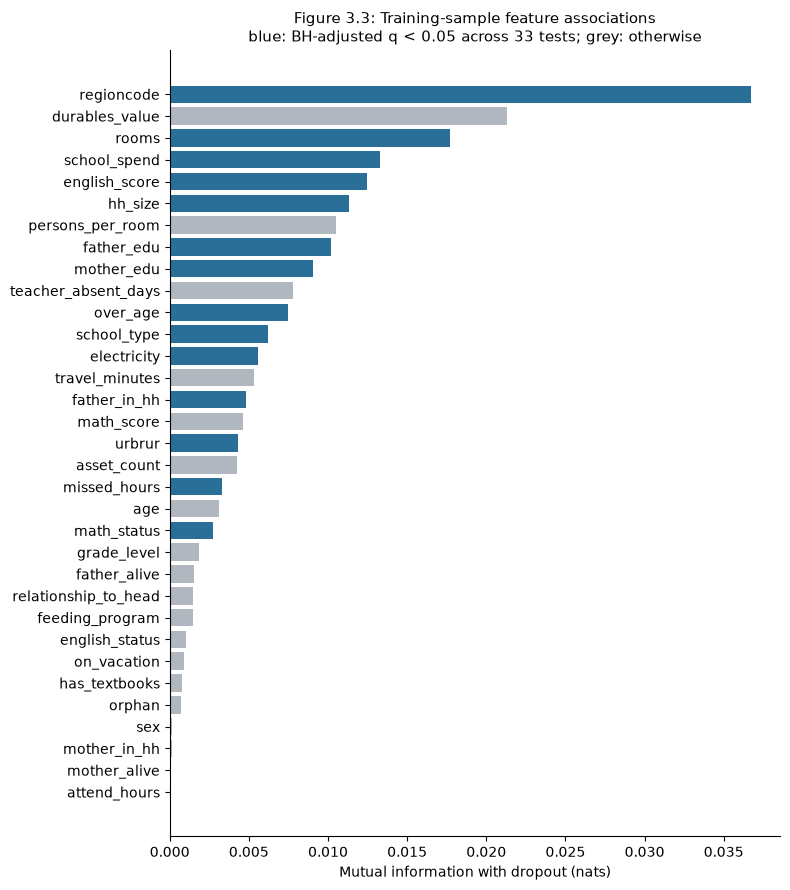

         feature       type               test            p    effect  Pearson chi2  df  minimum expected  cells expected <5  observed n  MC standard error     effect type              effect size  |effect|       MI            q  q-value (BY sensitivity) BH q<0.05
      regioncode    Nominal Pearson chi-square 2.608755e-20  0.294926    113.684905 9.0         10.356542                  0        1307                NaN      Cramer's V      Cramer's V = +0.295  0.294926 0.036719 8.608891e-19              3.520002e-18       yes
  durables_value Continuous     Mann-Whitney U 1.493183e-01  0.065816           NaN NaN               NaN                  0        1302                NaN rank-biserial r rank-biserial r = +0.066  0.065816 0.021320 2.463752e-01              1.000000e+00        no
           rooms   Discrete     Mann-Whitney U 2.003811e-04  0.165490           NaN NaN               NaN                  0        1302                NaN rank-biserial r rank-biserial r = +0.165  0.16549

In [12]:
# Reuse the exact Phase 1 sparse-aware, multiplicity-adjusted association audit.
imp = pd.read_csv(ROOT / "phase1_strategy/B4a_feature_target_tests.csv").rename(
    columns={"mutual information": "MI", "p-value": "p", "q-value (BH)": "q"}).sort_values("MI")
fig, ax = plt.subplots(figsize=(8, 9))
ax.barh(imp.feature, imp.MI, color=np.where(imp.q < .05, BLUE, GREY))
ax.set_xlabel("Mutual information with dropout (nats)")
ax.set_title("Figure 3.3: Training-sample feature associations\nblue: BH-adjusted q < 0.05 across 33 tests; grey: otherwise", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(FIG / "fig3_3_target_importance.png", bbox_inches="tight")
plt.show()
print(imp.sort_values("MI", ascending=False).head(8).to_string(index=False))


## 9. Figure 4.1: what the transformation stages do to one feature (daily travel time)

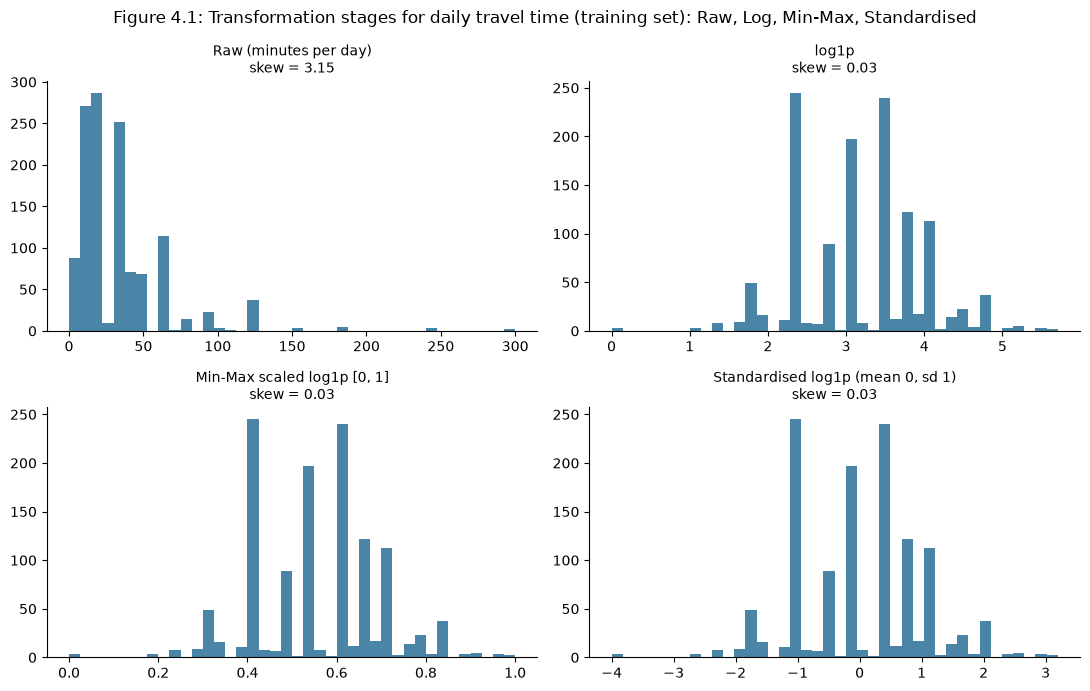

In [13]:
x = X_train["travel_minutes"].dropna().to_numpy().reshape(-1, 1)
lx = np.log1p(x)
stages = [("Raw (minutes per day)", x), ("log1p", lx),
          ("Min-Max scaled log1p [0, 1]", MinMaxScaler().fit_transform(lx)),
          ("Standardised log1p (mean 0, sd 1)", StandardScaler().fit_transform(lx))]
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, (title, v) in zip(axes.ravel(), stages):
    v = v.ravel()
    ax.hist(v, bins=40, color=BLUE, alpha=0.85)
    ax.set_title(f"{title}\nskew = {pd.Series(v).skew():.2f}", fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)
plt.suptitle("Figure 4.1: Transformation stages for daily travel time (training set): Raw, Log, Min-Max, Standardised", fontsize=12)
plt.tight_layout()
plt.savefig(FIG / "fig4_1_transformation_grid.png", bbox_inches="tight")
plt.show()

## 10. Figure 5.1: PCA scree and cumulative variance

PCA is fitted on the 48 standardised columns of the logistic-regression version of X_train (PCA needs a common scale). It shows how many combined components are needed to keep 90% and 95% of the variation.

Components needed: 21 of 48 for 90% of the variance, 28 for 95%


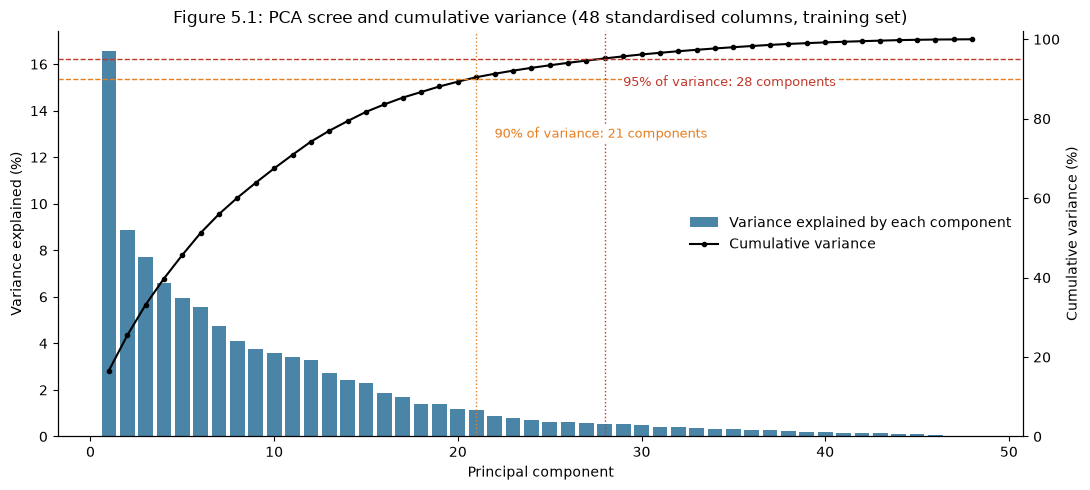

In [14]:
pca = PCA().fit(Xtr_lr)
ratio = pca.explained_variance_ratio_
cum = np.cumsum(ratio)
k90, k95 = int(np.argmax(cum >= 0.90) + 1), int(np.argmax(cum >= 0.95) + 1)
print(f"Components needed: {k90} of {len(ratio)} for 90% of the variance, {k95} for 95%")

fig, ax = plt.subplots(figsize=(11, 5))
idx = np.arange(1, len(ratio) + 1)
ax.bar(idx, ratio * 100, color=BLUE, alpha=0.85, label="Variance explained by each component")
ax.set_xlabel("Principal component"); ax.set_ylabel("Variance explained (%)")
ax2 = ax.twinx()
ax2.plot(idx, cum * 100, color="black", marker="o", markersize=3, lw=1.5, label="Cumulative variance")
for level, k, col in [(90, k90, "#e67e22"), (95, k95, RED)]:
    ax2.axhline(level, color=col, ls="--", lw=1)
    ax2.axvline(k, color=col, ls=":", lw=1)
    ax2.text(k + 1, level - 12 if level == 90 else level - 4, f"{level}% of variance: {k} components", color=col, fontsize=9,
             va="top", bbox=dict(facecolor="white", edgecolor="none", pad=1))
ax2.set_ylabel("Cumulative variance (%)"); ax2.set_ylim(0, 102)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="center right", frameon=False)
ax.spines[["top"]].set_visible(False); ax2.spines[["top"]].set_visible(False)
plt.title("Figure 5.1: PCA scree and cumulative variance (48 standardised columns, training set)", fontsize=12)
plt.tight_layout()
plt.savefig(FIG / "fig5_1_pca_scree_plot.png", bbox_inches="tight")
plt.show()
pd.DataFrame({"component": idx, "variance ratio": ratio, "cumulative variance": cum}).to_csv(
    OUT / "pca_variance.csv", index=False)


## 11. Other checks promised in Phase 1

* **Hours missed:** the rule "blank = 0 when attendance was recorded" is compared with simply filling the median.
* **Money after inflation adjustment:** where the testing children sit within the 2009/10 money ranks.
* **'Was missing' flags:** how often each flag is switched on in each period (no outcomes used).

In [15]:
r = MissedHoursRule().transform(X_train)
print(f"Hours missed: {int(X_train['missed_hours'].isna().sum() - r['missed_hours'].isna().sum())} blanks set to 0 by the rule; "
      f"{int(r['missed_hours'].isna().sum())} remain (holiday/unknown attendance) and are filled with the median")
print(f"Share reporting some hours missed when attendance was recorded: "
      f"2009/10 {((X_train['missed_hours'] > 0) & X_train['attend_hours'].notna()).sum() / X_train['attend_hours'].notna().sum():.1%}, "
      f"2013/14 {((X_test['missed_hours'] > 0) & X_test['attend_hours'].notna()).sum() / X_test['attend_hours'].notna().sum():.1%}")

for c in ["durables_value", "school_spend"]:
    print(f"{c}: typical rank of testing children against 2009/10 values = {Xte_xgb[c].median():.2f} "
          f"(0.50 would mean no real change)")

flags = [c for c in Xtr_xgb if c.endswith("_missing") and c != "school_type_missing"]
print(pd.DataFrame({"2009/10 (%)": (Xtr_xgb[flags].mean() * 100).round(1),
                    "2013/14 (%)": (Xte_xgb[flags].mean() * 100).round(1)}).to_string())

Hours missed: 756 blanks set to 0 by the rule; 261 remain (holiday/unknown attendance) and are filled with the median
Share reporting some hours missed when attendance was recorded: 2009/10 15.7%, 2013/14 14.4%
durables_value: typical rank of testing children against 2009/10 values = 0.63 (0.50 would mean no real change)
school_spend: typical rank of testing children against 2009/10 values = 0.39 (0.50 would mean no real change)
                             2009/10 (%)  2013/14 (%)
teacher_absent_days_missing         56.8         31.8
attend_hours_missing                21.8         11.7
father_edu_missing                   7.7          5.4
mother_edu_missing                   3.8          1.9


## 12. Quick end-to-end check with 5 district-grouped folds

This only checks that the full pipeline (preparation + model) runs fold by fold with fold-fitted preprocessing: every preparation step is re-fitted on the building part of each fold, and each dropout gets extra weight recalculated inside the fold. Model tuning, calibration and the single final test belong to the modelling phase, so **X_test outcomes are not used here**.

In [16]:
def cv_check(model, pipeline_fn=build_pipeline):
    pr, roc = [], []
    for a, b in cv.split(X_train, y_train, groups=X_train["district_id"]):
        ya = y_train.iloc[a]
        spw = (ya == 0).sum() / (ya == 1).sum()
        p = pipeline_fn(model, default_estimator(model, spw)).fit(X_train.iloc[a], ya)
        s = p.predict_proba(X_train.iloc[b])[:, 1]
        pr.append(average_precision_score(y_train.iloc[b], s)); roc.append(roc_auc_score(y_train.iloc[b], s))
    return np.mean(pr), np.std(pr), np.mean(roc)

def without_missed_rule(model, estimator):
    p = build_pipeline(model, estimator)
    p.steps[0] = ("missed_hours_rule", "passthrough")      # hours missed filled with the median instead
    return p

results = []
for m in ["lr", "xgb"]:
    for label, fn in [("Phase 1 plan", build_pipeline), ("hours missed: median instead of rule", without_missed_rule)]:
        mean_pr, sd_pr, mean_roc = cv_check(m, fn)
        results.append({"model": m, "variant": label, "PR-AUC (mean)": round(mean_pr, 3), "PR-AUC (sd)": round(sd_pr, 3), "ROC-AUC": round(mean_roc, 3)})
cv_results = pd.DataFrame(results)
print(cv_results.to_string(index=False))
print(f"\nReference: a model with no skill has PR-AUC equal to the dropout rate, {y_train.mean():.3f}")
cv_results.to_csv(OUT / "cv_results.csv", index=False)


model                              variant  PR-AUC (mean)  PR-AUC (sd)  ROC-AUC
   lr                         Phase 1 plan          0.266        0.072    0.627
   lr hours missed: median instead of rule          0.275        0.076    0.635
  xgb                         Phase 1 plan          0.252        0.089    0.602
  xgb hours missed: median instead of rule          0.257        0.091    0.610

Reference: a model with no skill has PR-AUC equal to the dropout rate, 0.144


## 13. Save the processed data and the decision log

In [17]:
def save(frame, X, y, name):
    if name.startswith("test"):
        frame = frame.assign(in_primary_test=test_cohorts.in_primary_test.to_numpy(dtype=int),
                             in_secondary_test=test_cohorts.in_secondary_test.to_numpy(dtype=int))
    out = pd.concat([X[ID_COLS].reset_index(drop=True), frame.reset_index(drop=True), y.reset_index(drop=True)], axis=1)
    out.to_csv(PROC / name, index=False)
    return out.shape

shapes = {
    "train_processed_xgb.csv": save(Xtr_xgb, X_train, y_train, "train_processed_xgb.csv"),
    "test_processed_xgb.csv": save(Xte_xgb.assign(in_both_tables=test_in_train.astype(int).values), X_test, y_test, "test_processed_xgb.csv"),
    "train_processed_lr.csv": save(Xtr_lr, X_train, y_train, "train_processed_lr.csv"),
    "test_processed_lr.csv": save(Xte_lr.assign(in_both_tables=test_in_train.astype(int).values), X_test, y_test, "test_processed_lr.csv"),
}
for k, v in shapes.items():
    print(f"data/processed/{k}: {v[0]} rows x {v[1]} columns")

data/processed/train_processed_xgb.csv: 1307 rows x 59 columns
data/processed/test_processed_xgb.csv: 1395 rows x 62 columns
data/processed/train_processed_lr.csv: 1307 rows x 54 columns
data/processed/test_processed_lr.csv: 1395 rows x 57 columns


In [18]:
planned = ("persons_per_room", "orphan", "grade_level")
n_match = int((fold_drops[["drop 1", "drop 2", "drop 3"]].apply(tuple, axis=1) == planned).sum())
lr_pr = cv_results.query("model == 'lr' and variant == 'Phase 1 plan'")["PR-AUC (mean)"].item()
lr_med = cv_results.query("model == 'lr' and variant != 'Phase 1 plan'")["PR-AUC (mean)"].item()
log = pd.DataFrame([
    ["Fix recording errors", "Fixed rules (codes, impossible values)", "Applied in 01_build_dataset; nothing learned", "As planned"],
    ["Inflation adjustment", "Convert 2013/14 money to 2009/10 prices (CPI)", f"Factor {CPI_FACTOR_W2_TO_W1:.2f} (World Bank CPI, weighted by interview months)", "Fixed external price adjustment; other distribution changes remain"],
    ["Split", "By time; primary new households; secondary new people", f"X_train {len(X_train)}, all temporal {len(X_test)}, primary {test_cohorts.in_primary_test.sum()}, secondary {test_cohorts.in_secondary_test.sum()}", "As planned"],
    ["Hours missed", "Blank = 0 when attendance recorded; median otherwise", f"Rule applied; CV PR-AUC (LR) {lr_pr} vs {lr_med} with median fill (descriptive comparison; uncertainty retained)", "Sensitivity comparison; no formal equivalence claim"],
    ["Was-missing flags", "4 flags before filling", "teacher absent, hours attended, father's and mother's education", "As planned"],
    ["Was-missing flags across periods", "Compare flags between periods", "Flags are on about half as often in 2013/14 (tablets) as in 2009/10 (paper)", "Confirmed limitation"],
    ["Filling gaps", "Mean / median / mode by skew; 'missing' option for school type", "SimpleImputer fitted on X_train", "As planned"],
    ["School grade", "Mixed-distance KNN with training-only k selection", f"Inner-grouped k={pre_xgb.named_steps['grade_knn'].n_neighbors_} on full training; over-age recalculated", "Revised and validated"],
    ["Repeating features", "Spearman |rho| >= 0.85, VIF > 10; drop 3; re-check in each fold", f"MI-only diagnostic matched the structural list in {n_match}/5 folds; removal is fixed from source identities/domain meaning, not MI; rebuilt exactly including unknowns", "Fixed structural list; MI-only check is descriptive"],
    ["Extreme values", "Log-IQR cap on travel, household size, rooms", f"Limits {', '.join(f'{v:.1f}' for v in limits.values())}; {sum(capped_train.values())} capped (train)", "As planned"],
    ["Money", "Rank 0-1 against model-building values", "TrainingRank fitted on X_train", "As planned"],
    ["Encoding", "One-hot, ordinal, 0/1", f"{Xtr_xgb.shape[1]} columns (XGBoost), {Xtr_lr.shape[1]} (LR)", "As planned"],
    ["Scaling", "None for XGBoost; log + StandardScaler for LR and PCA", f"PCA: {k90} components for 90%, {k95} for 95%", "As planned"],
    ["Cross-validation", "5 folds, stratified, grouped by district", "StratifiedGroupKFold; 0 shared districts or households", "As planned"],
    ["Class imbalance", "Class weighting, recalculated per fold", "scale_pos_weight / class_weight='balanced'", "As planned"],
    ["Calibration, final test", "Training-only nested tuning/calibration; frozen retrospective temporal evaluation", "Not run in Phase 2 (modelling phase)", "Deferred"],
], columns=["Step", "Planned in Phase 1", "Implemented in Phase 2", "Status"])
log.to_csv(OUT / "decision_log.csv", index=False)
pd.set_option("display.max_colwidth", 90)
print(log.to_string(index=False))

                            Step                                                                Planned in Phase 1                                                                                                                                          Implemented in Phase 2                                                             Status
            Fix recording errors                                            Fixed rules (codes, impossible values)                                                                                                                    Applied in 01_build_dataset; nothing learned                                                         As planned
            Inflation adjustment                                     Convert 2013/14 money to 2009/10 prices (CPI)                                                                                                      Factor 1.62 (World Bank CPI, weighted by interview months) Fixed external price adjustment; other di